In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import PowerTransformer, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score,recall_score,f1_score,confusion_matrix,classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier,VotingClassifier, BaggingClassifier,AdaBoostClassifier,GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
import joblib as jb



In [2]:
df_crop_prediction = pd.read_csv('Crop_recommendation.csv')

In [3]:
df_crop_prediction.head(30)

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice
5,69,37,42,23.058049,83.370118,7.073454,251.055000,rice
6,69,55,38,22.708838,82.639414,5.700806,271.324860,rice
7,94,53,40,20.277744,82.894086,5.718627,241.974195,rice
8,89,54,38,24.515881,83.535216,6.685346,230.446236,rice
9,68,58,38,23.223974,83.033227,6.336254,221.209196,rice


In [4]:
df_crop_prediction.info()

<class 'pandas.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   str    
dtypes: float64(4), int64(3), str(1)
memory usage: 153.0 KB


In [5]:
df_crop_prediction.describe()

,N,P,K,temperature,humidity,ph,rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


In [6]:
df_crop_prediction.duplicated().sum()

np.int64(0)

In [7]:
df_crop_prediction.isna().sum()

N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

In [8]:
df_crop_prediction['label'].value_counts()

label
rice           100
maize          100
chickpea       100
kidneybeans    100
pigeonpeas     100
mothbeans      100
mungbean       100
blackgram      100
lentil         100
pomegranate    100
banana         100
mango          100
grapes         100
watermelon     100
muskmelon      100
apple          100
orange         100
papaya         100
coconut        100
cotton         100
jute           100
coffee         100
Name: count, dtype: int64

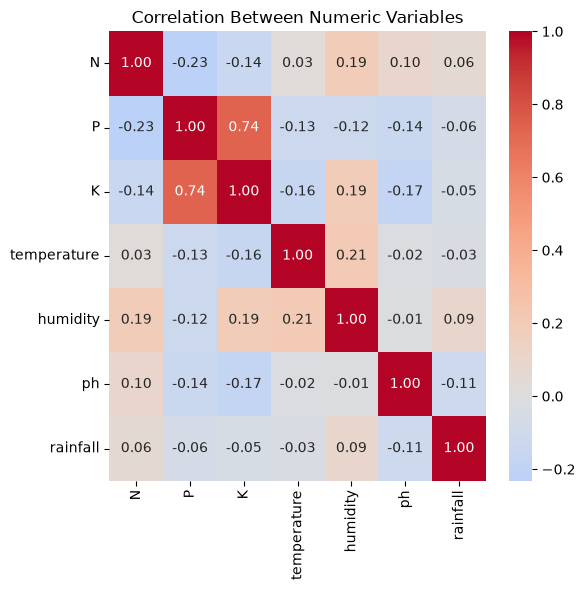

In [9]:
correlation = df_crop_prediction.select_dtypes(include=np.number).corr()

plt.figure(figsize=(6, 6))
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f', center=0)
plt.title('Correlation Between Numeric Variables')
plt.tight_layout()
plt.show()

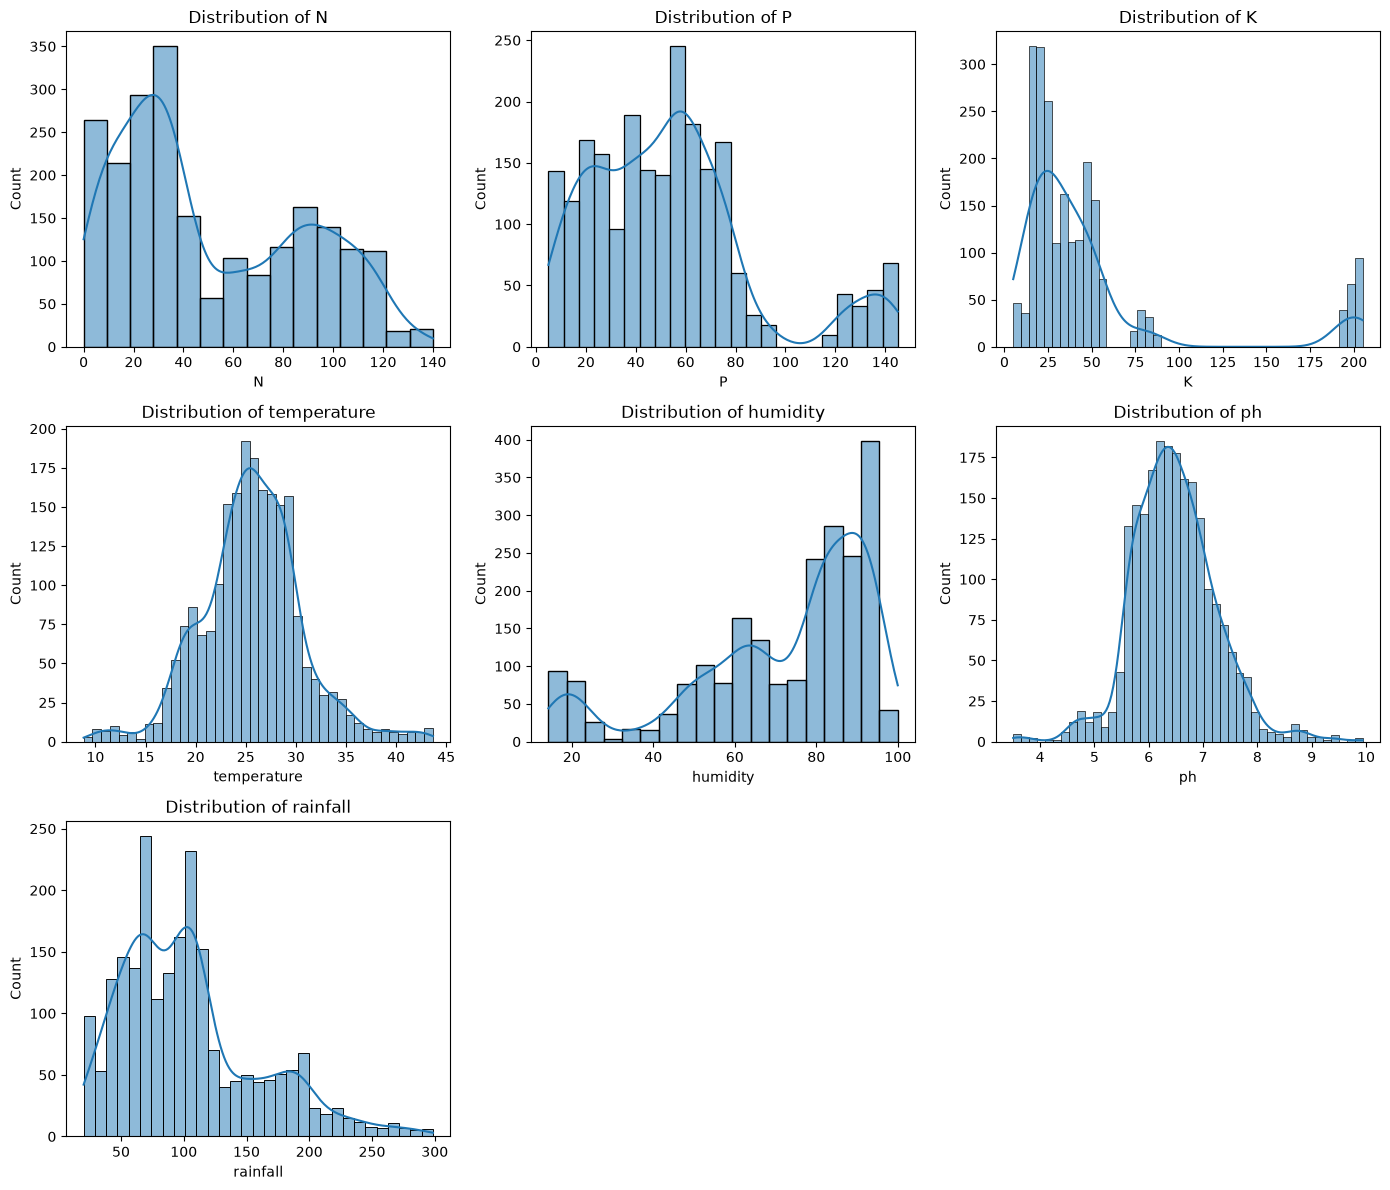

In [10]:
features = df_crop_prediction.select_dtypes(include=np.number).columns

dist_fig, dist_axes = plt.subplots(3, 3, figsize=(14, 12))
dist_axes = dist_axes.flatten()

for i, feature in enumerate(features):
  sns.histplot(data=df_crop_prediction, x=feature, kde=True, ax=dist_axes[i])
  dist_axes[i].set_title(f'Distribution of {feature}')

for ax in dist_axes[len(features):]:
  ax.set_visible(False)

dist_fig.tight_layout()
plt.show()

In [11]:
# data is slighltly skewed so we can use the power transformation to make it more normal distribution.
pt=PowerTransformer()
df_crop_prediction[features]=pt.fit_transform(df_crop_prediction[features])

<function matplotlib.pyplot.show(close=None, block=None)>

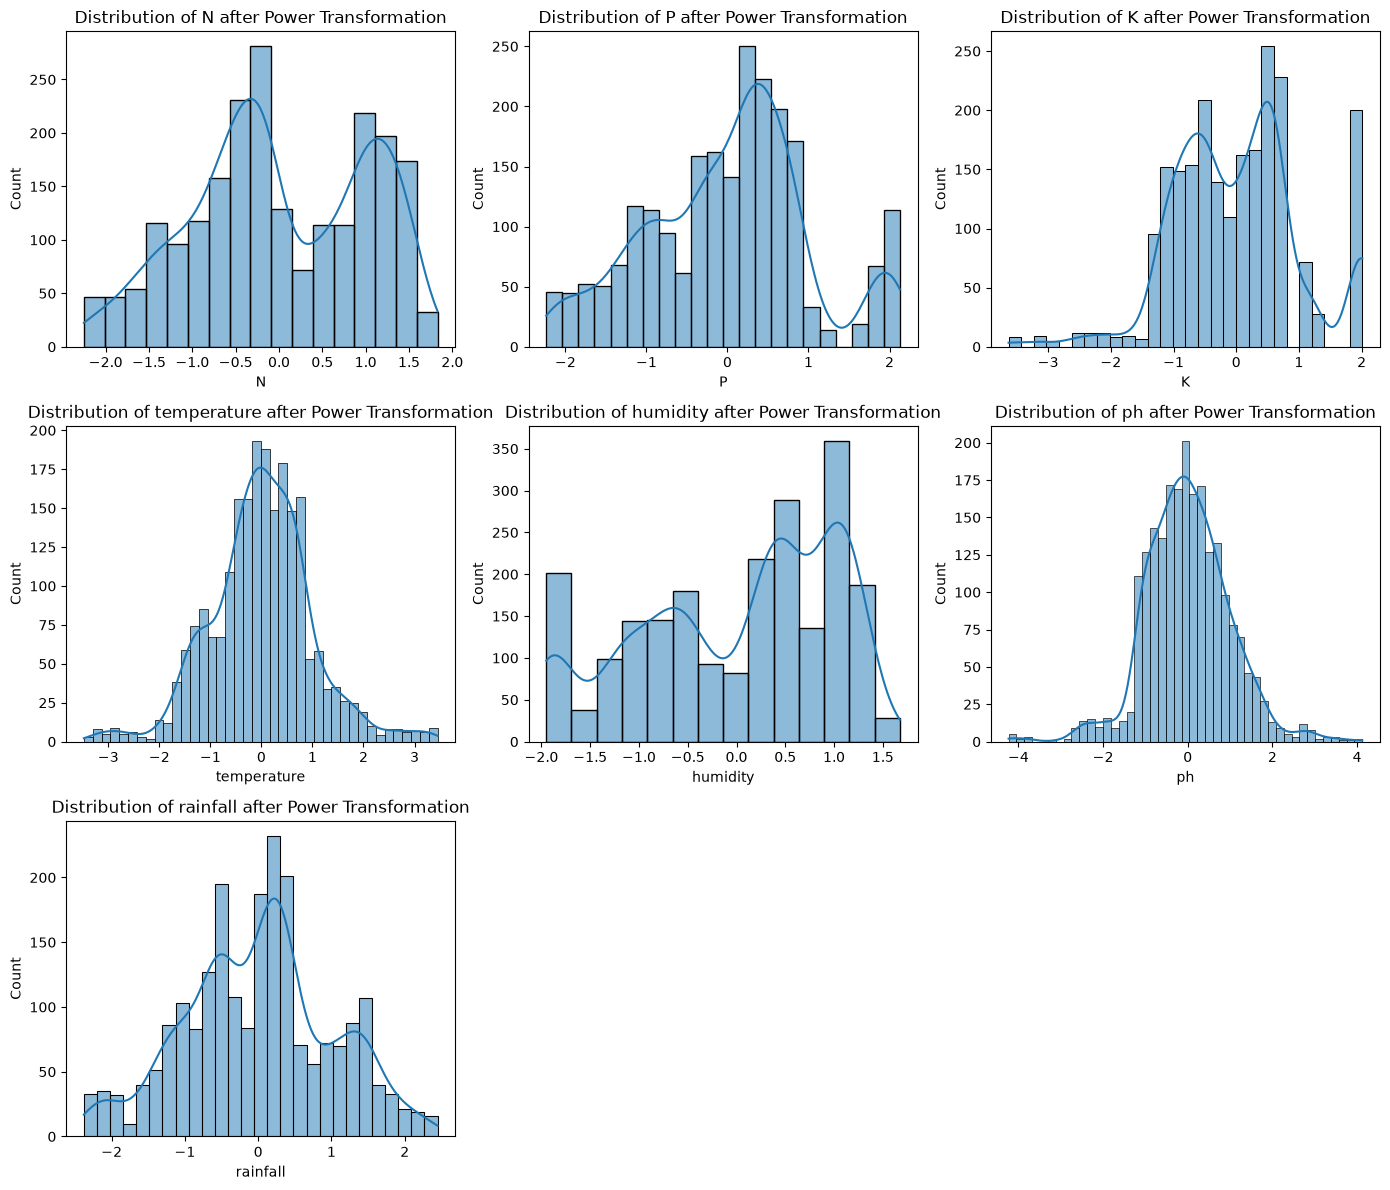

In [12]:
# now lets see again the distribution of variables after the power transformation
dist_fig, dist_axes = plt.subplots(3, 3, figsize=(14, 12))
dist_axes = dist_axes.flatten()

for i, feature in enumerate(features):
  sns.histplot(data=df_crop_prediction, x=feature, kde=True, ax=dist_axes[i])
  dist_axes[i].set_title(f'Distribution of {feature} after Power Transformation')

for ax in dist_axes[len(features):]:
  ax.set_visible(False)

dist_fig.tight_layout()
plt.show

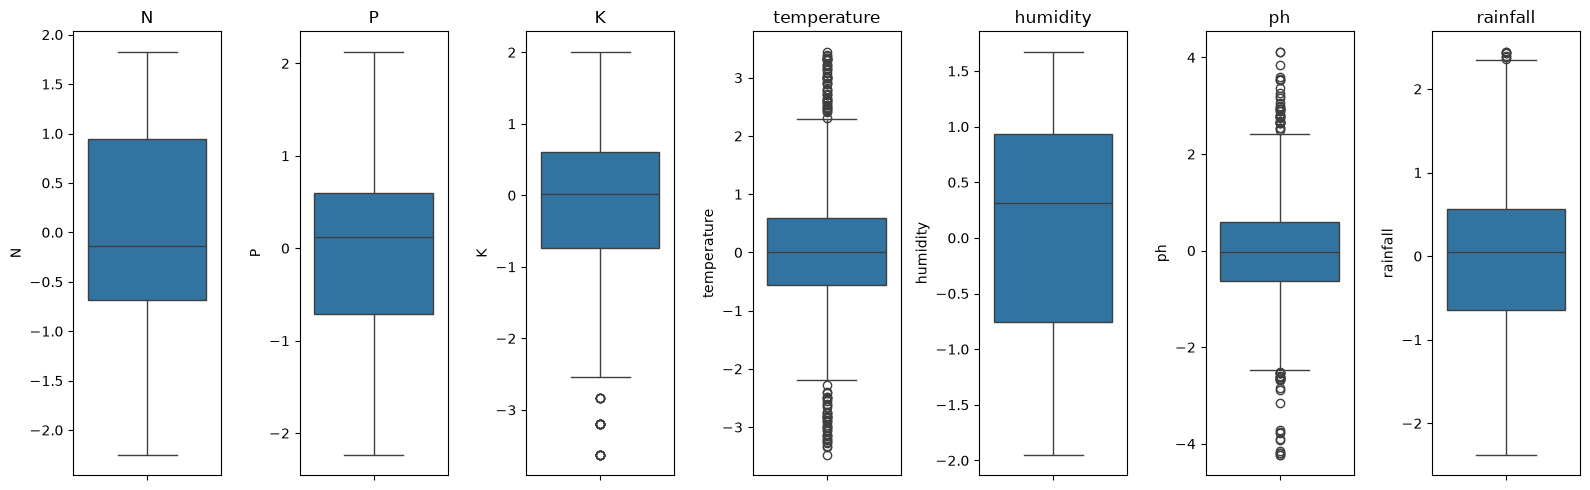

In [13]:
box_fig, box_axes = plt.subplots(1, len(features), figsize=(16, 5))

for box_ax, feature in zip(box_axes, features):
  sns.boxplot(y=df_crop_prediction[feature], ax=box_ax)
  box_ax.set_title(feature)

box_fig.tight_layout()
plt.show()

In [14]:
df_crop_prediction.shape

(2200, 8)

In [15]:
def finding_outliers(df, features):

    for feature in features:
        Q1 = df[feature].quantile(0.25)
        Q3 = df[feature].quantile(0.75)

        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        outlier_list_col = df[
            (df[feature] < lower_bound) |
            (df[feature] > upper_bound)
        ]

        print(f"{feature}: {outlier_list_col.shape[0]} outliers")

    return

In [16]:
finding_outliers(df_crop_prediction, ["temperature","ph","rainfall"])

temperature: 85 outliers
ph: 62 outliers
rainfall: 7 outliers


In [17]:
# here the outliers are more so  I am keeping them as it is because they are important for the model to learn the data better.

In [18]:
label_encoder = LabelEncoder()
df_crop_prediction['label'] = label_encoder.fit_transform(df_crop_prediction['label'])

In [19]:
for index, class_label in enumerate(label_encoder.classes_):
    print(f"Class {index}: {class_label}")

Class 0: apple
Class 1: banana
Class 2: blackgram
Class 3: chickpea
Class 4: coconut
Class 5: coffee
Class 6: cotton
Class 7: grapes
Class 8: jute
Class 9: kidneybeans
Class 10: lentil
Class 11: maize
Class 12: mango
Class 13: mothbeans
Class 14: mungbean
Class 15: muskmelon
Class 16: orange
Class 17: papaya
Class 18: pigeonpeas
Class 19: pomegranate
Class 20: rice
Class 21: watermelon


In [20]:
df_crop_prediction

,N,P,K,temperature,humidity,ph,rainfall,label
0,1.051047,-0.169541,0.430166,-0.933044,0.405334,0.066186,1.572569,20
1,0.960517,0.328412,0.366477,-0.753510,0.300993,0.746037,1.815966,20
2,0.453737,0.242156,0.460529,-0.506220,0.425326,1.728702,2.160912,20
3,0.749884,-0.424458,0.333035,0.184225,0.291124,0.673719,1.970950,20
4,0.828446,-0.169541,0.398834,-1.084836,0.380446,1.473277,2.150027,20
...,...,...,...,...,...,...,...,...
2195,1.338761,-0.463341,0.017445,0.239875,-0.467769,0.420793,1.288484,5
2196,1.206941,-1.395097,-0.239543,0.365711,-0.910316,-0.477363,0.615847,5
2197,1.511006,-0.502927,-0.078439,-0.281689,-0.427420,-0.115679,1.234961,5
2198,1.495743,-0.543248,0.105607,0.141257,-1.087767,0.393770,0.604262,5


In [21]:
model = ["Logistic Regression","Naive Bayes","Decision Tree","Random Forest","Voting Ensemble","Bagging"
,"SVM","KNN","Adaboost","GradientBoost"]


In [22]:
x_data = df_crop_prediction.drop(columns= ['label'])
y_data = df_crop_prediction['label']
x_data

,N,P,K,temperature,humidity,ph,rainfall
0,1.051047,-0.169541,0.430166,-0.933044,0.405334,0.066186,1.572569
1,0.960517,0.328412,0.366477,-0.753510,0.300993,0.746037,1.815966
2,0.453737,0.242156,0.460529,-0.506220,0.425326,1.728702,2.160912
3,0.749884,-0.424458,0.333035,0.184225,0.291124,0.673719,1.970950
4,0.828446,-0.169541,0.398834,-1.084836,0.380446,1.473277,2.150027
...,...,...,...,...,...,...,...
2195,1.338761,-0.463341,0.017445,0.239875,-0.467769,0.420793,1.288484
2196,1.206941,-1.395097,-0.239543,0.365711,-0.910316,-0.477363,0.615847
2197,1.511006,-0.502927,-0.078439,-0.281689,-0.427420,-0.115679,1.234961
2198,1.495743,-0.543248,0.105607,0.141257,-1.087767,0.393770,0.604262


In [23]:
x_train, x_test , y_train , y_test  = train_test_split(x_data,y_data,test_size=0.20,random_state=45)

In [24]:
accuracy_train = []
accuracy_test = []

precision_train = []
precision_test = []

recall_train = []
recall_test = []

f1_train = []
f1_test = []

def evaluate_model(model,x_train,y_train,x_test,y_test):

  
    model.fit(x_train, y_train)

    y_pred_train = model.predict(x_train)
    y_pred_test = model.predict(x_test)

    # Accuracy
    accuracy_score_train = accuracy_score(y_train, y_pred_train)
    accuracy_score_test = accuracy_score(y_test, y_pred_test)

    accuracy_train.append(accuracy_score_train)
    accuracy_test.append(accuracy_score_test)

    precision_score_train = precision_score(
        y_train, y_pred_train, average="weighted", zero_division=0
    )
    precision_score_test = precision_score(
        y_test, y_pred_test, average="weighted", zero_division=0
    )

    precision_train.append(precision_score_train)
    precision_test.append(precision_score_test)

    recall_score_train = recall_score(
        y_train, y_pred_train, average="weighted", zero_division=0
    )
    recall_score_test = recall_score(
        y_test, y_pred_test, average="weighted", zero_division=0
    )

    recall_train.append(recall_score_train)
    recall_test.append(recall_score_test)

    f1_score_train = f1_score(
        y_train, y_pred_train, average="weighted", zero_division=0
    )
    f1_score_test = f1_score(
        y_test, y_pred_test, average="weighted", zero_division=0
    )

    f1_train.append(f1_score_train)
    f1_test.append(f1_score_test)

    print(f"{model.__class__.__name__} Performance Metrics:")
    print(f"Training Data: Accuracy = {accuracy_score_train:.2f}%, Precision = {precision_score_train:.2f}%, "
          f"Recall = {recall_score_train:.2f}%, F1 = {f1_score_train:.2f}%")
    print(f"Testing Data : Accuracy = {accuracy_score_test:.2f}%, Precision = {precision_score_test:.2f}%, "
          f"Recall = {recall_score_test:.2f}%, F1 = {f1_score_test:.2f}%")

    print("\nConfusion Matrix (Test):")
    print(confusion_matrix(y_test,y_pred_test))
    print("\nClassification Report(Test)")
    print(classification_report(y_test,y_pred_test))

  
  

In [25]:
# Logistic Classifier
evaluate_model(
  LogisticRegression(),
  x_train,
  y_train,
  x_test,
  y_test
)

LogisticRegression Performance Metrics:
Training Data: Accuracy = 0.98%, Precision = 0.98%, Recall = 0.98%, F1 = 0.98%
Testing Data : Accuracy = 0.97%, Precision = 0.97%, Recall = 0.97%, F1 = 0.97%

Confusion Matrix (Test):
[[14  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0 20  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0 14  0  0  0  0  0  0  0  2  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0 19  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0 17  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0 18  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0 24  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0 18  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  1  0  0 19  0  0  0  0  0  0  0  0  1  0  0  1  0]
 [ 0  0  0  0  0  0  0  0  0 20  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0 26  0  0  1  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0 

In [26]:
#Naive Bayes
evaluate_model(
  GaussianNB(),
  x_train,
  y_train,
  x_test,
  y_test
)

GaussianNB Performance Metrics:
Training Data: Accuracy = 0.99%, Precision = 1.00%, Recall = 0.99%, F1 = 0.99%
Testing Data : Accuracy = 1.00%, Precision = 1.00%, Recall = 1.00%, F1 = 1.00%

Confusion Matrix (Test):
[[14  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0 20  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0 16  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0 19  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0 17  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0 18  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0 24  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0 18  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0 21  0  0  0  0  0  0  0  0  0  0  0  1  0]
 [ 0  0  0  0  0  0  0  0  0 20  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0 27  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  1  0

In [27]:
#decision tree
evaluate_model(
  DecisionTreeClassifier(),
  x_train,
  y_train,
  x_test,
  y_test
)

DecisionTreeClassifier Performance Metrics:
Training Data: Accuracy = 1.00%, Precision = 1.00%, Recall = 1.00%, F1 = 1.00%
Testing Data : Accuracy = 0.99%, Precision = 0.99%, Recall = 0.99%, F1 = 0.99%

Confusion Matrix (Test):
[[14  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0 20  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0 16  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0 19  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0 17  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0 18  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0 24  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0 18  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  1  0  0 21  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0 20  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0 26  0  0  1  0  0  0  0  0  0  0  0]
 [ 0  0  0  0

In [28]:
#Random forest
evaluate_model(
  RandomForestClassifier(),
  x_train,
  y_train,
  x_test,
  y_test
)

RandomForestClassifier Performance Metrics:
Training Data: Accuracy = 1.00%, Precision = 1.00%, Recall = 1.00%, F1 = 1.00%
Testing Data : Accuracy = 1.00%, Precision = 1.00%, Recall = 1.00%, F1 = 1.00%

Confusion Matrix (Test):
[[14  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0 20  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0 16  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0 19  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0 17  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0 18  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0 24  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0 18  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0 21  0  0  0  0  0  0  0  0  0  0  0  1  0]
 [ 0  0  0  0  0  0  0  0  0 20  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0 27  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0

In [29]:
#Voting ensemble
evaluate_model(
VotingClassifier(estimators=[('m1',LogisticRegression()),('m2',DecisionTreeClassifier()),('m3',RandomForestClassifier())]),
  x_train,
  y_train,
  x_test,
  y_test
)

VotingClassifier Performance Metrics:
Training Data: Accuracy = 1.00%, Precision = 1.00%, Recall = 1.00%, F1 = 1.00%
Testing Data : Accuracy = 0.99%, Precision = 0.99%, Recall = 0.99%, F1 = 0.99%

Confusion Matrix (Test):
[[14  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0 20  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0 16  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0 19  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0 17  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0 18  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0 24  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0 18  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0 21  0  0  0  0  0  0  0  0  0  0  0  1  0]
 [ 0  0  0  0  0  0  0  0  0 20  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0 27  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0

In [30]:
#Bagging
evaluate_model(
BaggingClassifier(estimator=LogisticRegression()),
  x_train,
  y_train,
  x_test,
  y_test
)

BaggingClassifier Performance Metrics:
Training Data: Accuracy = 0.98%, Precision = 0.98%, Recall = 0.98%, F1 = 0.98%
Testing Data : Accuracy = 0.96%, Precision = 0.96%, Recall = 0.96%, F1 = 0.96%

Confusion Matrix (Test):
[[14  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0 20  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0 14  0  0  0  0  0  0  0  2  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0 19  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0 17  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0 18  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0 24  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0 18  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  1  0  0 19  0  0  0  0  0  0  0  0  1  0  0  1  0]
 [ 0  0  0  0  0  0  0  0  0 20  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0 26  0  0  1  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  

In [31]:
#SVM
evaluate_model(
  SVC(),
  x_train,
  y_train,
  x_test,
  y_test
)

SVC Performance Metrics:
Training Data: Accuracy = 0.99%, Precision = 0.99%, Recall = 0.99%, F1 = 0.99%
Testing Data : Accuracy = 0.98%, Precision = 0.98%, Recall = 0.98%, F1 = 0.98%

Confusion Matrix (Test):
[[14  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0 20  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0 15  0  0  0  0  0  0  0  1  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0 19  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0 17  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0 18  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0 24  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0 18  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0 22  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0 20  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  1  0  0  0  0  0  0  0 26  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  1  0  0  0 

In [32]:
#KNN
evaluate_model(
  KNeighborsClassifier(),
  x_train,
  y_train,
  x_test,
  y_test
)

KNeighborsClassifier Performance Metrics:
Training Data: Accuracy = 0.99%, Precision = 0.99%, Recall = 0.99%, F1 = 0.99%
Testing Data : Accuracy = 0.97%, Precision = 0.98%, Recall = 0.97%, F1 = 0.97%

Confusion Matrix (Test):
[[14  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0 20  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0 15  0  0  0  0  0  0  0  1  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0 19  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0 17  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0 18  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0 24  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0 18  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0 21  0  0  0  0  0  0  0  0  0  0  0  1  0]
 [ 0  0  0  0  0  0  0  0  0 20  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  1  0  0  0  0  0  0  0 26  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  

In [33]:
#adaboost
evaluate_model(
  AdaBoostClassifier(),
  x_train,
  y_train,
  x_test,
  y_test
)

AdaBoostClassifier Performance Metrics:
Training Data: Accuracy = 0.19%, Precision = 0.09%, Recall = 0.19%, F1 = 0.10%
Testing Data : Accuracy = 0.19%, Precision = 0.10%, Recall = 0.19%, F1 = 0.11%

Confusion Matrix (Test):
[[ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0 14  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0 20  0  0  0  0]
 [ 0  0  0  0  0 16  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0 19  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0 14  0  3  0  0]
 [ 0  0  0  0  0 18  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0 24  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0 18  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0 22  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0 20  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0 27  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0 

e:\Data Science_ML_AL_NLP\deployment\project-2\myenv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
e:\Data Science_ML_AL_NLP\deployment\project-2\myenv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
e:\Data Science_ML_AL_NLP\deployment\project-2\myenv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, 

In [34]:
#gradientboost
evaluate_model(
  GradientBoostingClassifier(),
  x_train,
  y_train,
  x_test,
  y_test
)

GradientBoostingClassifier Performance Metrics:
Training Data: Accuracy = 1.00%, Precision = 1.00%, Recall = 1.00%, F1 = 1.00%
Testing Data : Accuracy = 0.99%, Precision = 0.99%, Recall = 0.99%, F1 = 0.99%

Confusion Matrix (Test):
[[14  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0 20  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0 16  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0 19  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0 17  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0 18  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0 24  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0 18  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0 21  0  0  0  0  0  0  0  0  0  0  0  1  0]
 [ 0  0  0  0  0  0  0  0  0 20  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0 26  0  0  1  0  0  0  0  0  0  0  0]
 [ 0  0  

In [35]:
pd.DataFrame({
    "Model": model,
    "Accuracy Train": accuracy_train,
    "Accuracy Test": accuracy_test,
    "Precision Train": precision_train,
    "Precision Test": precision_test,
    "Recall Train": recall_train,
    "Recall Test": recall_test,
    "F1 Train": f1_train,
    "F1 Test": f1_test
})

,Model,Accuracy Train,Accuracy Test,Precision Train,Precision Test,Recall Train,Recall Test,F1 Train,F1 Test
0,Logistic Regression,0.977841,0.965909,0.978152,0.966047,0.977841,0.965909,0.977891,0.965381
1,Naive Bayes,0.994886,0.995455,0.995200,0.995627,0.994886,0.995455,0.994867,0.995435
2,Decision Tree,1.000000,0.986364,1.000000,0.987079,1.000000,0.986364,1.000000,0.986387
3,Random Forest,1.000000,0.997727,1.000000,0.997808,1.000000,0.997727,1.000000,0.997722
4,Voting Ensemble,1.000000,0.993182,1.000000,0.993316,1.000000,0.993182,1.000000,0.993190
5,Bagging,0.978409,0.963636,0.978819,0.963897,0.978409,0.963636,0.978412,0.963130
6,SVM,0.987500,0.979545,0.988952,0.980704,0.987500,0.979545,0.987382,0.979501
7,KNN,0.986932,0.975000,0.987693,0.975861,0.986932,0.975000,0.986869,0.974879
8,Adaboost,0.185795,0.193182,0.085666,0.097805,0.185795,0.193182,0.101098,0.111503
9,GradientBoost,1.000000,0.993182,1.000000,0.993281,1.000000,0.993182,1.000000,0.993186


In [36]:
# From above report we can say that random forest is the best.
rf = RandomForestClassifier()
rf.fit(x_train,y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [37]:
jb.dump(rf,'randomForest_crop_prediction.pkl')
jb.dump(pt,'powerTransformer_crop_prediction.pkl')
jb.dump(label_encoder,"label_encoder_crop_prediction.pkl")

['label_encoder_crop_prediction.pkl']